# 1.04 · MiBici preprocessing: station-hour features

**Phase 1 (data preparation)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `1.02` because it reads that notebook's output.

- **Input:** `data/processed/mibici/` (cleaned trips) and the station nomenclature.
- **Output:** `data/processed/mibici/features/station_hour_features.parquet`, tracked in MLflow, plus the preprocessing pipeline definition in `team2_mlops2026.features`.

The [ML Canvas](../references/ml-canvas.md) frames the task as forecasting the **hourly departures and arrivals of every station** so the operator can rebalance bikes. This notebook turns the trips into that table and justifies how each column is transformed before modelling:

1. Build the station-hour table (targets, lagged demand, calendar and station attributes).
2. Why each transformation: scaling of skewed counts, cyclical encoding, categorical encoding.
3. Time-based train/test split.
4. Fit the preprocessing on the training split only and check the result.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc

import numpy as np
import pandas as pd
from sklearn import set_config

from team2_mlops2026 import eda, plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.features import (
    DEMAND_FEATURES,
    STATION,
    TARGETS,
    TIME,
    WEEKDAY,
    create_features_tracked,
    make_preprocessor,
    time_split,
)

pd.set_option("display.max_columns", 50)
set_config(display="text")  # the HTML diagram embeds thousands of lines of CSS in the notebook
plots.use_style()

2026-10-24 14:32:58.301 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: /Users/xavier/code/tecmty/mlops/fase1Proyecto/MLOps_Team2


## Parameters

The table starts in 2023, on the post-COVID plateau (`1.03` §2); 2020-2021 is a regime change. The test split is the last 12 months, the backtest window of the ML Canvas.

In [3]:
START = "2023-01"  # first month of the table (the 4 weeks before only feed the lags)
TEST_START = "2025-10"  # last 12 months as test
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

## 1. Build the station-hour table

`create_features_tracked()` aggregates the processed trips into one row per station and hour while the station is active (first to last hour with any trip), **zero hours included**. Each row holds:

- **Targets:** departures (by start hour) and arrivals (by end hour).
- **Lagged demand:** the same quantity 2 days and 7 days before, and the mean of the same hour over the previous 4 weeks. Only hours known when the next-day forecast is made (>= 48 h back); hours before a station opened are unknown, not zero.
- **Calendar:** weekday, and hour and month as sin/cos.
- **Station:** latitude, longitude and capacity from the nomenclature.

The run is tracked in MLflow (`build-station-hour-features`): the processed trips and stations as inputs, the feature table as output (each with a digest), the feature definition as params and the table's shape as metrics.

In [4]:
summary = create_features_tracked(start=START)
print(f"MLflow run {summary['mlflow_run_id']} in experiment '{MLFLOW_EXPERIMENT_NAME}' ({MLFLOW_TRACKING_URI})")

features = pd.read_parquet(summary["path"])
print(f"{len(features):,} station-hours x {features.shape[1]} columns "
      f"({features.memory_usage(deep=True).sum() / 2**30:.2f} GB in memory)")
print(f"{features[STATION].nunique()} stations, {features[TIME].min()} -> {features[TIME].max()}")
features.head()

/Users/xavier/code/tecmty/mlops/fase1Proyecto/MLOps_Team2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-10-24 14:33:18.312 | SUCCESS  | team2_mlops2026.features:create_features:293 - Features: 12,180,583 station-hours, 486 stations, 2023-01-01 00:00:00 -> 2026-09-30 23:00:00


🏃 View run build-station-hour-features at: http://127.0.0.1:5001/#/experiments/1/runs/b960d3b389ac4d9f98cc1c5db54fdbdd
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
MLflow run b960d3b389ac4d9f98cc1c5db54fdbdd in experiment 'mibici' (http://127.0.0.1:5001)


12,180,583 station-hours x 18 columns (1.19 GB in memory)
486 stations, 2023-01-01 00:00:00 -> 2026-09-30 23:00:00


,station_id,hour_start,departures,arrivals,departures_lag_2d,departures_lag_7d,departures_same_hour_4w,arrivals_lag_2d,arrivals_lag_7d,arrivals_same_hour_4w,weekday,hour_sin,hour_cos,month_sin,month_cos,latitude,longitude,capacity
0,2,2023-01-01 00:00:00,0,0,0.0,0.0,0.333333,0.0,0.0,0.333333,6,0.000000,1.000000,0.0,1.0,20.666378,-103.34882,15.0
1,2,2023-01-01 01:00:00,0,0,0.0,0.0,0.000000,0.0,0.0,0.000000,6,0.258819,0.965926,0.0,1.0,20.666378,-103.34882,15.0
2,2,2023-01-01 02:00:00,0,0,0.0,0.0,0.000000,0.0,0.0,0.000000,6,0.500000,0.866025,0.0,1.0,20.666378,-103.34882,15.0
3,2,2023-01-01 03:00:00,0,0,0.0,0.0,0.000000,0.0,0.0,0.000000,6,0.707107,0.707107,0.0,1.0,20.666378,-103.34882,15.0
4,2,2023-01-01 04:00:00,0,0,0.0,0.0,0.000000,0.0,0.0,0.000000,6,0.866025,0.500000,0.0,1.0,20.666378,-103.34882,15.0


In [5]:
eda.data_quality(features)

,dtype,missing,missing_pct,n_unique
station_id,int64,0,0.000000,486
hour_start,datetime64[us],0,0.000000,32856
departures,int32,0,0.000000,108
arrivals,int32,0,0.000000,123
departures_lag_2d,float32,8258,0.067796,108
departures_lag_7d,float32,28898,0.237246,108
departures_same_hour_4w,float32,28898,0.237246,316
arrivals_lag_2d,float32,8258,0.067796,123
arrivals_lag_7d,float32,28898,0.237246,123
arrivals_same_hour_4w,float32,28898,0.237246,427


**Result → action.** The table holds 12,180,583 station-hours for 486 stations, from 2023-01-01 to 2026-09-30 (1.19 GB in memory). Targets and calendar columns are complete.
- The lags are missing in 0.07-0.24% of the rows: the first days and weeks of new stations, whose earlier hours are unknown, not zero demand.
- Location is missing in 0.28% of the rows: ids 124, 405 and 407, which are absent from the nomenclature (`1.02` T8).
- Capacity is also missing in 1.36% of the rows: those three ids plus four retired `ex-ZPN` stations (99, 109, 116, 138) that the nomenclature lists with capacity 0.

→ Median imputation inside the pipeline, fitted on the training rows only.

## 2. Why each transformation

### 2.1 Demand counts are sparse and right-skewed → `log1p` + standard scaling

In [6]:
zero = (features[list(TARGETS)] == 0).mean() * 100
print(f"Station-hours with zero departures: {zero['departures']:.1f}%, zero arrivals: {zero['arrivals']:.1f}%")
eda.univariate_summary(features[[*TARGETS, *DEMAND_FEATURES]])

Station-hours with zero departures: 54.6%, zero arrivals: 55.1%


,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
arrivals_same_hour_4w,12151685.0,1.327914,2.335938,0.0,0.0,0.5,1.75,109.75,0.5,6.825800,125.586739
arrivals_lag_7d,12151685.0,1.331684,2.590125,0.0,0.0,0.0,2.00,210.00,0.0,6.496086,116.166992
arrivals_lag_2d,12172325.0,1.333544,2.593117,0.0,0.0,0.0,2.00,210.00,0.0,6.488212,115.766731
arrivals,12180583.0,1.335082,2.595542,0.0,0.0,0.0,2.00,210.00,0.0,6.486892,115.688903
departures_lag_7d,12151685.0,1.331685,2.456471,0.0,0.0,0.0,2.00,205.00,0.0,4.716582,58.809090
departures_lag_2d,12172325.0,1.333545,2.459682,0.0,0.0,0.0,2.00,205.00,0.0,4.714612,58.631664
departures,12180583.0,1.335083,2.461994,0.0,0.0,0.0,2.00,205.00,0.0,4.712123,58.498593
departures_same_hour_4w,12151685.0,1.327949,2.182054,0.0,0.0,0.5,1.75,77.00,0.5,4.525024,46.762718


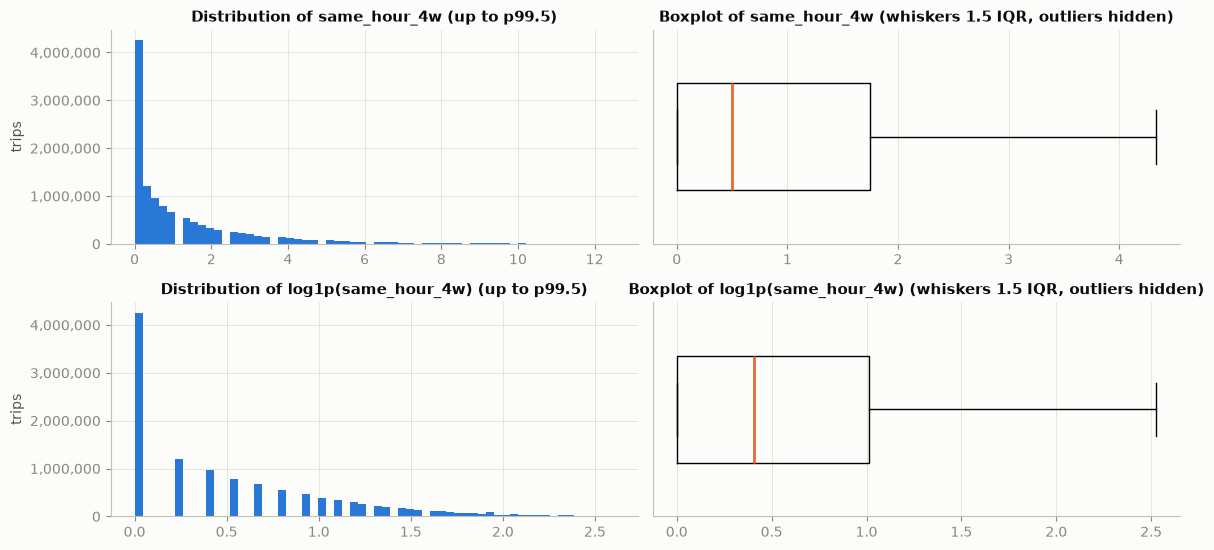

In [7]:
lag = features["departures_same_hour_4w"].dropna()
plots.plot_hist_box(pd.DataFrame({"same_hour_4w": lag, "log1p(same_hour_4w)": np.log1p(lag)}));

**Result → action.** 54.6% of station-hours have no departures and 55.1% no arrivals. The median is 0, while the busiest hour reaches 205 departures (skewness 4.7 and kurtosis 58; 6.5 and 116 for arrivals), and the lags share that shape. On the raw scale, a few downtown peak hours would dominate the mean and standard deviation used for scaling. `log1p` compresses that tail (histograms above) while keeping 0 at 0.

→ Lagged counts go through median imputation, `log1p` and standard scaling. The targets themselves are left as counts: their sparsity is why the ML Canvas proposes a Poisson or Tweedie loss for the model.

### 2.2 Hour and month are cyclical → sin/cos

As plain numbers, 23:00 and 00:00 are 23 units apart although they are consecutive hours, and December is 11 months from January. Mapping each onto a circle keeps neighbours close.

In [8]:
angle = 2 * np.pi * np.arange(24) / 24
hour_points = pd.DataFrame({"hour_sin": np.sin(angle), "hour_cos": np.cos(angle)})


def distance(a: int, b: int) -> float:
    return float(np.hypot(*(hour_points.loc[a] - hour_points.loc[b])))


pd.DataFrame(
    {"as a number": [23, 12, 1], "sin/cos": [distance(23, 0), distance(0, 12), distance(8, 9)]},
    index=["23:00 vs 00:00", "00:00 vs 12:00", "08:00 vs 09:00"],
).round(2)

,as a number,sin/cos
23:00 vs 00:00,23,0.26
00:00 vs 12:00,12,2.00
08:00 vs 09:00,1,0.26


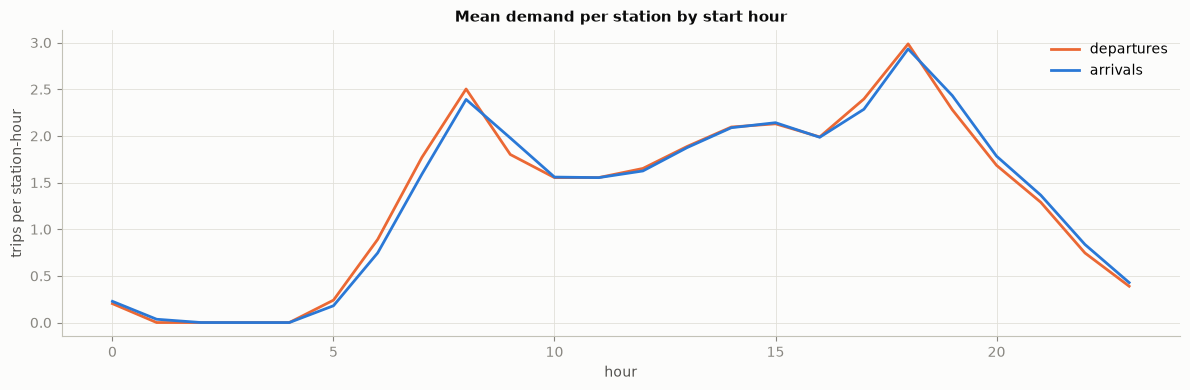

In [9]:
by_hour = features.groupby(features[TIME].dt.hour)[list(TARGETS)].mean()
plots.plot_lines(by_hour, "Mean demand per station by start hour", "trips per station-hour", xlabel="hour");

**Result → action.** As plain numbers, 23:00 and 00:00 are the two hours furthest apart (distance 23), although they are consecutive. On the circle they are as close as 08:00 and 09:00 (0.26), and noon is the hour furthest from midnight (2.0). Demand by hour is not monotonic: it peaks at 8:00 and 18:00 and is almost zero from 1:00 to 5:00, so no linear term in the hour could capture it.

→ Hour and month enter as sin/cos pairs. Both are already in [-1, 1], so they pass through unscaled.

### 2.3 Weekday is categorical, not ordinal → one-hot

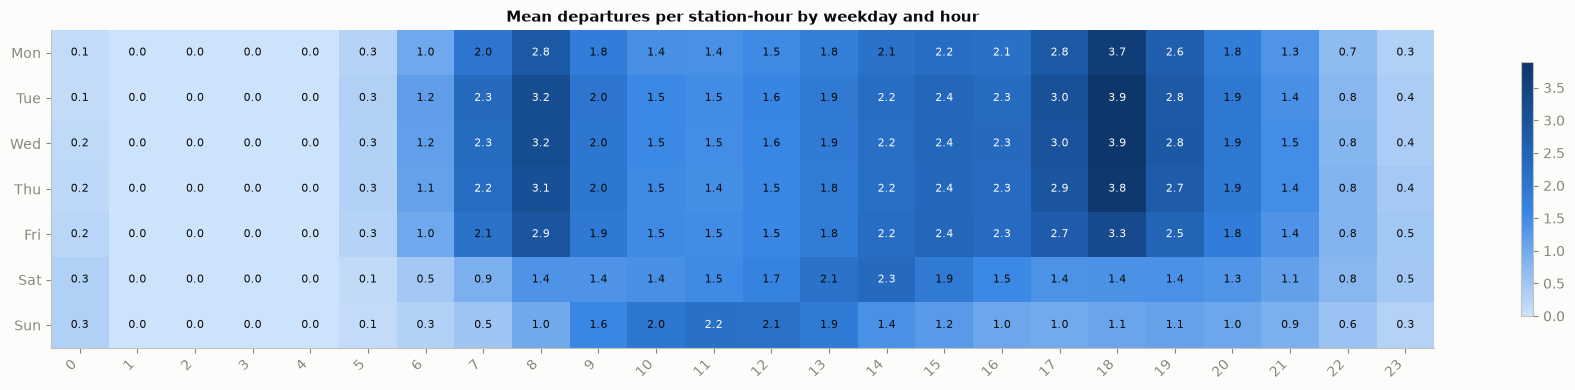

In [10]:
weekday_hour = features.pivot_table(
    index=WEEKDAY, columns=features[TIME].dt.hour, values="departures", aggfunc="mean"
)
weekday_hour.index = WEEKDAYS
plots.plot_heatmap(weekday_hour, "Mean departures per station-hour by weekday and hour", fmt="{:.1f}", figsize=(18, 4));

**Result → action.** Monday to Friday share the commuter profile: the busiest hour is 18:00, with up to 3.9 departures per station-hour on Tuesday and Wednesday, followed by 8:00. Saturday has a flat midday plateau, and Sunday a single peak at 10:00-12:00. The weekday is a category with no order: Sunday is not "one more" than Saturday, and the morning peak exists only on weekdays.

→ One-hot encoding with 7 columns (`handle_unknown="ignore"`). A model can combine these columns with the hour encoding to learn the weekday × hour interaction.

### 2.4 Station id has high cardinality → target encoding

In [11]:
per_station = features.groupby(STATION)["departures"].mean()
print(f"{len(per_station)} station ids: one-hot would add {len(per_station)} columns, "
      f"each {1 - 1 / len(per_station):.1%} zeros")
per_station.describe().to_frame("mean departures per station-hour").T

486 station ids: one-hot would add 486 columns, each 99.8% zeros


,count,mean,std,min,25%,50%,75%,max
mean departures per station-hour,486.0,1.129564,1.182947,0.0,0.357284,0.744838,1.581783,10.362795


**Result → action.** There are 486 station ids. One-hot encoding would add 486 columns, each 99.8% zeros. The station's demand level is what matters: mean departures per station-hour range from 0 to 10.4 (median 0.74, interquartile range 0.36-1.58).

→ Target encoding replaces each id with a single column, holding the station's mean departures in the training data. The encoder shrinks the means of stations with few hours toward the global mean.

## 3. Time-based split

A random split would put future hours in training and leak future demand (`1.03` findings). Training is everything before `TEST_START`; the test set is the last 12 months.

In [12]:
train, test = time_split(features, TEST_START)
del features
gc.collect()

new_stations = sorted(set(test[STATION]) - set(train[STATION]))
display(pd.DataFrame(
    {
        "rows": [len(train), len(test)],
        "from": [train[TIME].min(), test[TIME].min()],
        "to": [train[TIME].max(), test[TIME].max()],
        "stations": [train[STATION].nunique(), test[STATION].nunique()],
    },
    index=["train", "test"],
))
print(f"Stations that only appear in test: {len(new_stations)} {new_stations}")

,rows,from,to,stations
train,8603903,2023-01-01,2025-09-30 23:00:00,384
test,3576680,2025-10-01,2026-09-30 23:00:00,484


Stations that only appear in test: 102 [401, 402, 405, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 439, 440, 441, 442, 443, 444, 445, 446, 448, 449, 450, 451, 452, 453, 454, 455, 456, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 470, 471, 472, 473, 478, 479, 480, 481, 483, 484, 485, 487, 488, 489, 490, 491, 493, 494, 496, 497, 498, 500, 501, 503, 504, 505, 506, 507, 508, 509, 510, 511, 512, 513, 514, 515, 516, 517, 518, 519]


**Result → action.** Train has 8,603,903 station-hours (2023-01 to 2025-09, 384 stations) and test 3,576,680 (2025-10 to 2026-09, 484 stations). **102 stations exist only in test.** Two opened at the end of 2025 and 100 between May and August 2026 (12, 47, 27 and 14 per month), so the network grew by about a quarter. This matches the record volume of September 2026 seen in `1.03` §2. The new stations average 0.42 departures per hour, against 1.27 for the existing ones, and carry 2.3% of test departures.

→ Model evaluation must report new and existing stations separately. The training data contains no information about these stations.

## 4. Fit the preprocessing on the training split only

`make_preprocessor()` is a scikit-learn `ColumnTransformer`. Every statistic it learns (scaling means and deviations, imputation medians, station encodings) comes from the training rows only; the test rows are only transformed. The target encoder uses departures and is **cross-fitted** inside the training set (5 folds), so a training row is never encoded with its own target.

In [13]:
preprocessor = make_preprocessor()
X_train = preprocessor.fit_transform(train, train["departures"])
X_test = preprocessor.transform(test)
print(f"Train: {X_train.shape}, test: {X_test.shape}, missing values after preprocessing: "
      f"{int(X_train.isna().sum().sum() + X_test.isna().sum().sum())}")
preprocessor

Train: (8603903, 21), test: (3576680, 21), missing values after preprocessing: 0


ColumnTransformer(transformers=[('station',
                                 TargetEncoder(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                                               target_type='continuous'),
                                 ['station_id']),
                                ('weekday',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['weekday']),
                                ('cyclical', 'passthrough',
                                 ['hour_sin', 'hour_cos', 'month_sin',
                                  'month_cos']),
                                ('demand',
                                 Pipeline(steps=[('simpleimputer',...
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
           

In [14]:
pd.DataFrame(
    {
        "train_mean": X_train.mean(),
        "train_std": X_train.std(),
        "test_mean": X_test.mean(),
        "test_std": X_test.std(),
    }
).round(3)

,train_mean,train_std,test_mean,test_std
station__station_id,1.386,1.290,1.342,1.222
weekday__weekday_0,0.143,0.350,0.143,0.350
weekday__weekday_1,0.143,0.351,0.143,0.350
weekday__weekday_2,0.142,0.349,0.145,0.352
weekday__weekday_3,0.142,0.349,0.142,0.349
weekday__weekday_4,0.142,0.350,0.142,0.349
weekday__weekday_5,0.143,0.350,0.142,0.350
weekday__weekday_6,0.143,0.350,0.143,0.350
cyclical__hour_sin,-0.000,0.707,-0.000,0.707
cyclical__hour_cos,-0.000,0.707,-0.000,0.707


In [15]:
encoded = X_train["station__station_id"].groupby(train[STATION].to_numpy()).mean()
observed = train.groupby(STATION)["departures"].mean()
unseen = preprocessor.named_transformers_["station"].target_mean_
print(f"Correlation between a station's encoding and its observed mean departures: {encoded.corr(observed):.3f}")
print(f"Encoding given to stations unseen in training (global mean): {unseen:.3f}")

Correlation between a station's encoding and its observed mean departures: 1.000
Encoding given to stations unseen in training (global mean): 1.386


**Result → action.** The pipeline produces 21 columns, with no missing values in either split. On the training rows, every scaled column has mean 0 and standard deviation 1 by construction. On the test rows, the demand lags are 0.08-0.09 standard deviations lower, because the new low-demand stations pull the per-station mean down. This shift appears without any model being trained: it is input drift that monitoring must track (ML Canvas §10).

The target encoding reproduces each known station's mean (correlation 1.000). All 102 new stations receive the same value, the global mean of 1.386, so the encoding carries no station-specific information for them.

→ For new stations, the model has to rely on location, capacity and, after their first weeks, their own lags. A station usage-profile feature (#9) would also help. This puts a number on the "network changes" risk listed in the ML Canvas.

## Findings and next steps

**Feature table**
- `data/processed/mibici/features/station_hour_features.parquet` holds 12.2M station-hours for 486 stations, from 2023-01 to 2026-09.
- Each row has two targets (departures and arrivals), 6 lagged-demand features, calendar features and station attributes.
- Every build is an MLflow run (`build-station-hour-features`), with the digests of its input trips and stations and of its output. `python -m team2_mlops2026.features` rebuilds it in about 20 s.

**Preprocessing (`make_preprocessor`, fitted on the training split only)**
- *Normalization:* `log1p` and standard scaling for the skewed lagged counts; standard scaling for location and capacity.
- *Categorical encoding:* one-hot for the weekday (7 values, not ordinal); cross-fitted target encoding for the station id (486 values).
- *Cyclical encoding:* sin/cos for hour and month.
- *Missing values:* median imputation for unknown lags (new stations) and for stations missing from the nomenclature.
- The target encoder is fitted on departures. An arrivals model fits its own copy with `make_preprocessor().fit(train, train["arrivals"])`.

**Implications for the next stages**
- *Network expansion:* about 100 stations opened between May and August 2026. Evaluation must split new and existing stations, and monitoring must track the per-station demand level as well as total volume.
- *Dimensionality reduction (#9):* a PCA of each station's hour-of-week profile can give new stations a usage-profile feature once they have a few weeks of history.
- *Modelling (phase 2):* the targets are sparse counts, so the first models are the baselines of the ML Canvas, followed by gradient boosting with a Poisson or Tweedie objective.